<a href="https://colab.research.google.com/github/MikelOyarzabal/proyecto-videojuegos/blob/main/proyecto_videojuegos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto de Análisis de datos — Ventas de videojuegos (VGChartz 2024)

**Pregunta general del proyecto:** ¿qué factores se asocian al éxito comercial de un videojuego?

Hilo del análisis:

1. **P1 – Concentración.** ¿Cómo se reparten las ventas entre los juegos? ¿Es un mercado de unos pocos superventas?
2. **P2 – Género.** Si las ventas están tan concentradas, ¿el género se asocia a vender más?
3. **P3 – Mercados.** ¿Ese efecto del género es igual en todas las regiones, o cada mercado (Norteamérica, Europa, Japón) prefiere géneros y fabricantes distintos?
4. **P4 – Evolución.** ¿Han cambiado estas preferencias entre 1995 y 2018?
5. **P5 – Crítica.** Una vez vistos género, mercado y momento, ¿la nota de la crítica se relaciona con las ventas? ¿Igual en todos los géneros?


## 0. Instalación y carga de paquetes

In [ ]:
paquetes <- c("readr", "dplyr", "tidyr", "stringr", "forcats", "lubridate", "ggplot2", "scales")
faltan <- paquetes[!paquetes %in% rownames(installed.packages())]
if (length(faltan) > 0) install.packages(faltan)
suppressPackageStartupMessages(invisible(lapply(paquetes, library, character.only = TRUE)))

theme_set(theme_minimal(base_size = 12))
options(repr.plot.width = 10, repr.plot.height = 6, dplyr.summarise.inform = FALSE)
set.seed(123)

## 1. Carga de los datos

Fuente: *Video Game Sales 2024* (Kaggle, datos de VGChartz), fichero `vgchartz-2024.csv`.

Para que el notebook se ejecute de principio a fin en Colab, lo ideal es leer el CSV desde una **URL pública** (por ejemplo, el enlace *Raw* de un repositorio de GitHub). Para una prueba rápida, también se puede subir el fichero a `/content` con el panel de archivos.

In [ ]:
# Cambiar por la URL raw de GitHub (recomendado) o dejar el nombre si se ha subido a /content
ruta_datos <- "https://raw.githubusercontent.com/MikelOyarzabal/proyecto-videojuegos/main/vgchartz-2024.csv"

vg_raw <- read_csv(ruta_datos, show_col_types = FALSE)
dim(vg_raw)
glimpse(vg_raw)

[1] 64016    14

Rows: 64,016
Columns: 14
$ img          <chr> "/games/boxart/full_6510540AmericaFrontccc.jpg", "/games/…
$ title        <chr> "Grand Theft Auto V", "Grand Theft Auto V", "Grand Theft …
$ console      <chr> "PS3", "PS4", "PS2", "X360", "PS4", "X360", "X360", "PS4"…
$ genre        <chr> "Action", "Action", "Action", "Action", "Shooter", "Shoot…
$ publisher    <chr> "Rockstar Games", "Rockstar Games", "Rockstar Games", "Ro…
$ developer    <chr> "Rockstar North", "Rockstar North", "Rockstar North", "Ro…
$ critic_score <dbl> 9.4, 9.7, 9.6, NA, 8.1, 8.7, 8.8, 9.8, 8.4, 8.0, 9.5, 8.1…
$ total_sales  <dbl> 20.32, 19.39, 16.15, 15.86, 15.09, 14.82, 14.74, 13.94, 1…
$ na_sales     <dbl> 6.37, 6.06, 8.41, 9.06, 6.18, 9.07, 9.76, 5.26, 8.27, 4.9…
$ jp_sales     <dbl> 0.99, 0.60, 0.47, 0.06, 0.41, 0.13, 0.11, 0.21, 0.07, 0.6…
$ pal_sales    <dbl> 9.85, 9.71, 5.49, 5.33, 6.05, 4.29, 3.73, 6.21, 4.32, 5.8…
$ other_sales  <dbl> 3.12, 3.02, 1.78, 1.42, 2.44, 1.33, 1.14, 2.26, 1.20, 2.2…
$ release_date 

## 2. Exploración inicial

### 2.1 Valores ausentes por variable

In [ ]:
ausentes <- vg_raw |>
  summarise(across(everything(), ~ sum(is.na(.x)))) |>
  pivot_longer(everything(), names_to = "variable", values_to = "n_ausentes") |>
  mutate(pct_ausentes = round(100 * n_ausentes / nrow(vg_raw), 1)) |>
  arrange(desc(pct_ausentes))
ausentes

variable,n_ausentes,pct_ausentes
<chr>,<int>,<dbl>
critic_score,57338,89.6
jp_sales,57290,89.5
na_sales,51379,80.3
pal_sales,51192,80.0
other_sales,48888,76.4
last_update,46137,72.1
total_sales,45094,70.4
release_date,7051,11.0
img,0,0.0


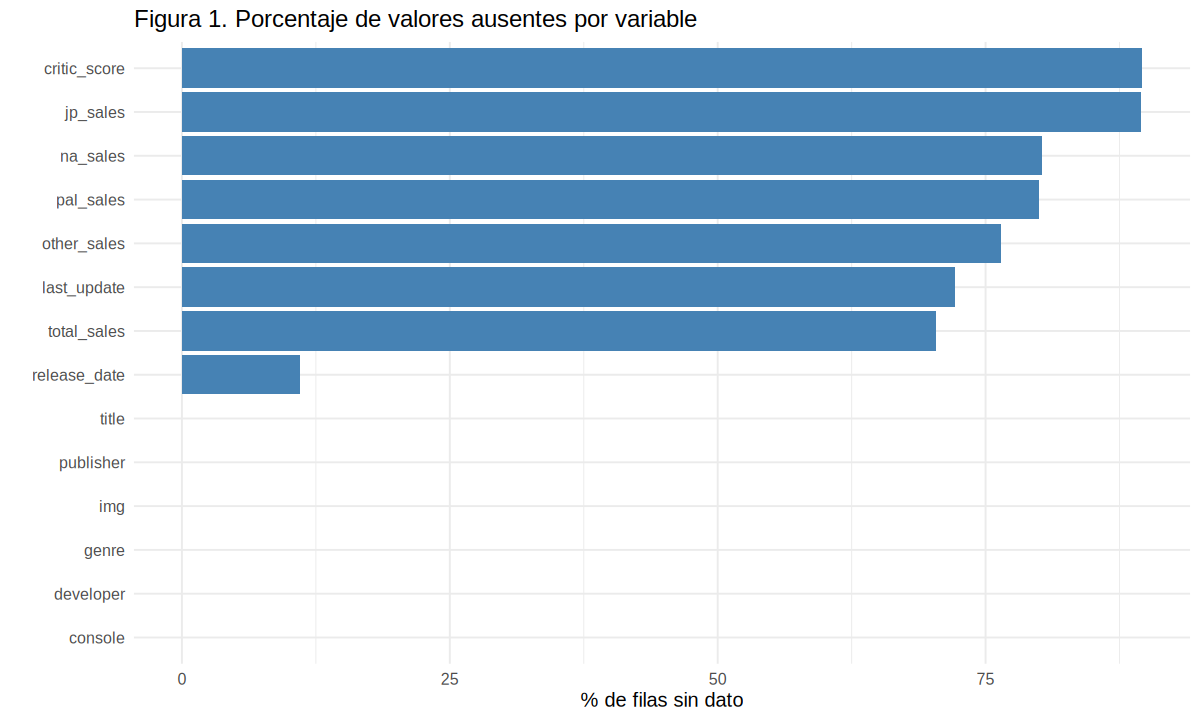

In [ ]:
ggplot(ausentes, aes(x = reorder(variable, pct_ausentes), y = pct_ausentes)) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(title = "Figura 1. Porcentaje de valores ausentes por variable",
       x = NULL, y = "% de filas sin dato")

### 2.2 Variables categóricas y otros problemas detectados

In [ ]:
cat("Consolas distintas:", n_distinct(vg_raw$console), "\n")
cat("Géneros distintos:", n_distinct(vg_raw$genre), "\n")
cat("Editores distintos:", n_distinct(vg_raw$publisher), "\n\n")

cat("Filas con consola 'All':", sum(vg_raw$console == "All"),
    "| de ellas con ventas:", sum(vg_raw$console == "All" & !is.na(vg_raw$total_sales)), "\n")
cat("Editor 'Unknown':", sum(vg_raw$publisher == "Unknown"),
    "| Desarrollador 'Unknown':", sum(vg_raw$developer == "Unknown", na.rm = TRUE), "\n")
cat("Filas duplicadas exactas:", sum(duplicated(vg_raw)), "\n")
cat("Duplicados título + consola:", sum(duplicated(vg_raw[, c("title", "console")])), "\n")
cat("Juegos con total_sales = 0:", sum(vg_raw$total_sales == 0, na.rm = TRUE), "\n")

Consolas distintas: 81 
Géneros distintos: 20 
Editores distintos: 3383 

Filas con consola 'All': 1138 | de ellas con ventas: 0 
Editor 'Unknown': 8842 | Desarrollador 'Unknown': 4435 
Filas duplicadas exactas: 0 
Duplicados título + consola: 225 
Juegos con total_sales = 0: 1352 


### 2.3 ¿Las ventas regionales vacías son 'cero' o 'dato perdido'?

Si `total_sales` coincide con la suma de las regiones tratando los `NA` como 0, la interpretación más razonable es que un `NA` regional significa *sin ventas registradas en esa región*.

In [ ]:
chequeo <- vg_raw |>
  filter(!is.na(total_sales)) |>
  mutate(suma_regiones = rowSums(across(c(na_sales, jp_sales, pal_sales, other_sales)), na.rm = TRUE),
         diferencia = abs(total_sales - suma_regiones))

cat("Juegos con ventas totales:", nrow(chequeo), "\n")
cat("% con diferencia > 0.02 M entre total y suma regional:",
    round(100 * mean(chequeo$diferencia > 0.02), 2), "%\n")

Juegos con ventas totales: 18922 
% con diferencia > 0.02 M entre total y suma regional: 0.04 %


## 3. Limpieza y preparación

Decisiones (a justificar en el informe):

| Problema | Decisión | Motivo |
|---|---|---|
| Columnas `img` y `last_update` | Eliminar | No aportan al análisis |
| Consola `"All"` | Eliminar filas | Son fichas agregadas, ninguna tiene ventas |
| `publisher` / `developer` = `"Unknown"` | Convertir a `NA` | Es un dato ausente, no una categoría |
| `release_date` | Convertir a fecha y extraer `anio` | Necesario para el análisis temporal |
| Juegos sin `total_sales` | Fuera del subconjunto de análisis | La variable objetivo es la venta |
| `total_sales = 0` | Excluir | Está por debajo de la resolución del registro (< 5.000 unidades) y no permite el logaritmo |
| Ventas regionales `NA` (con total) | Imputar 0 | El total coincide con la suma regional (apartado 2.3) |
| Duplicados título + consola con ventas | Quedarse con el registro de mayores ventas | Son el mismo juego en la misma plataforma; afecta a < 0,5 % |
| 81 consolas | Agrupar por **fabricante** | Demasiadas categorías para comparar |
| Géneros con < 100 juegos | Agrupar en `"Otros"` | Grupos demasiado pequeños para contrastes |

In [ ]:
vg <- vg_raw |>
  select(-img, -last_update) |>
  filter(console != "All") |>
  mutate(
    publisher = na_if(publisher, "Unknown"),
    developer = na_if(developer, "Unknown"),
    release_date = as.Date(release_date),
    anio = year(release_date)
  )

cat("Filas tras eliminar consola 'All':", nrow(vg), "\n")

Filas tras eliminar consola 'All': 62878 


### 3.1 Agrupación de consolas por fabricante

In [ ]:
sony      <- c("PS", "PS2", "PS3", "PS4", "PS5", "PSP", "PSV", "PSN")
nintendo  <- c("NES", "SNES", "N64", "GC", "Wii", "WiiU", "NS", "GB", "GBC", "GBA",
               "DS", "DSi", "DSiW", "3DS", "VC", "VB", "iQue", "FDS", "WW")
microsoft <- c("XB", "X360", "XOne", "XS", "XBL", "Series")
sega      <- c("GEN", "SAT", "DC", "MS", "GG", "SCD", "S32X")
pc        <- c("PC", "OSX", "Linux", "WinP")

vg <- vg |>
  mutate(fabricante = case_when(
    console %in% sony      ~ "Sony",
    console %in% nintendo  ~ "Nintendo",
    console %in% microsoft ~ "Microsoft",
    console %in% sega      ~ "Sega",
    console %in% pc        ~ "PC",
    TRUE                   ~ "Otros"
  ))

count(vg, fabricante, sort = TRUE)

fabricante,n
<chr>,<int>
Nintendo,17689
Sony,16619
PC,13730
Microsoft,7884
Otros,3869
Sega,3087


### 3.2 Subconjunto de análisis: juegos con ventas

In [ ]:
ventas <- vg |>
  filter(!is.na(total_sales), total_sales > 0) |>
  mutate(across(c(na_sales, jp_sales, pal_sales, other_sales), ~ replace_na(.x, 0)))

# Duplicados título + consola: se conserva el registro con más ventas
n_antes <- nrow(ventas)
ventas <- ventas |>
  arrange(desc(total_sales)) |>
  distinct(title, console, .keep_all = TRUE)
cat("Duplicados eliminados:", n_antes - nrow(ventas), "\n")
cat("Juegos en el subconjunto de análisis:", nrow(ventas), "\n")

Duplicados eliminados: 53 
Juegos en el subconjunto de análisis: 17517 


### 3.3 Nuevas variables

In [ ]:
# Géneros pequeños -> "Otros"
ventas <- ventas |>
  mutate(genero = fct_lump_min(genre, min = 100, other_level = "Otros"))

ventas <- ventas |>
  mutate(
    log_ventas = log10(total_sales),                       # ventas en millones, escala log10
    # Región donde más vende el juego (Otros mercados es residual: < 1 % de los juegos)
    region_principal = case_when(
      na_sales  >= pmax(jp_sales, pal_sales, other_sales) ~ "Norteamérica",
      pal_sales >= pmax(jp_sales, other_sales)            ~ "Europa",
      jp_sales  >= other_sales                            ~ "Japón",
      TRUE                                                ~ "Otros"
    ),
    periodo = cut(anio, breaks = c(1994, 1999, 2004, 2009, 2014, 2018),
                  labels = c("1995-99", "2000-04", "2005-09", "2010-14", "2015-18")),
    tiene_critica = !is.na(critic_score)
  )

count(ventas, genero, sort = TRUE)
count(ventas, region_principal, sort = TRUE)
count(ventas, periodo)

genero,n
<fct>,<int>
Action,2673
Sports,2479
Misc,1825
Adventure,1680
Role-Playing,1408
Shooter,1374
Racing,1346
Simulation,1003
Platform,901


region_principal,n
<chr>,<int>
Norteamérica,10590
Japón,4420
Europa,2437
Otros,70


periodo,n
<fct>,<int>
1995-99,1290
2000-04,3098
2005-09,5986
2010-14,4207
2015-18,2478
NA,458


### 3.4 Valores atípicos

Las ventas son muy asimétricas. Los superventas **no son errores**: son justo el fenómeno que se estudia en P1, así que **no se eliminan**. Se marcan con el criterio IQR sobre la escala logarítmica.

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.0100  0.0500  0.1400  0.3766  0.3800 20.3200 

Juegos atípicos por arriba (escala log): 34 | umbral: 7.96 M


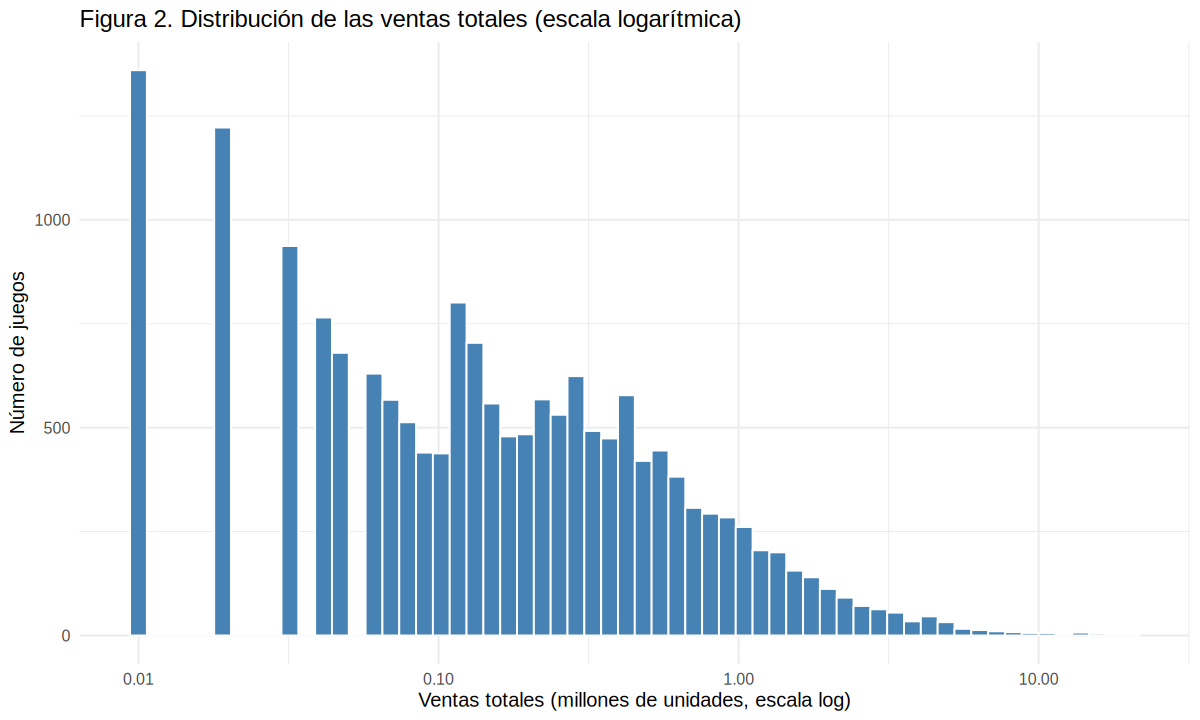

In [ ]:
summary(ventas$total_sales)

q <- quantile(ventas$log_ventas, c(.25, .75))
limite_sup <- q[2] + 1.5 * diff(q)
ventas <- ventas |> mutate(atipico = log_ventas > limite_sup)
cat("Juegos atípicos por arriba (escala log):", sum(ventas$atipico),
    "| umbral:", round(10^limite_sup, 2), "M\n")

ggplot(ventas, aes(x = total_sales)) +
  geom_histogram(bins = 60, fill = "steelblue", colour = "white") +
  scale_x_log10(labels = label_number(accuracy = 0.01)) +
  labs(title = "Figura 2. Distribución de las ventas totales (escala logarítmica)",
       x = "Ventas totales (millones de unidades, escala log)", y = "Número de juegos")

---
## P1. ¿Está concentrado el mercado en unos pocos superventas?

**Qué se quiere averiguar:** qué parte de las ventas se llevan los juegos más vendidos.
**Por qué importa:** si la distribución es muy desigual, la media no es representativa y los análisis siguientes tendrán que usar medianas, escala logarítmica o pruebas no paramétricas.
**Técnica:** estadística descriptiva, curva de Lorenz e índice de Gini.

In [ ]:
gini <- function(x) {
  x <- sort(x); n <- length(x)
  sum((2 * seq_len(n) - n - 1) * x) / (n * sum(x))
}

orden <- sort(ventas$total_sales, decreasing = TRUE)
cuota_top <- function(p) sum(orden[seq_len(ceiling(p * length(orden)))]) / sum(orden)

tibble(
  media = mean(ventas$total_sales),
  mediana = median(ventas$total_sales),
  gini = gini(ventas$total_sales),
  cuota_top1  = cuota_top(0.01),
  cuota_top10 = cuota_top(0.10),
  cuota_top20 = cuota_top(0.20)
) |> mutate(across(everything(), ~ round(.x, 3)))

media,mediana,gini,cuota_top1,cuota_top10,cuota_top20
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.377,0.14,0.685,0.168,0.545,0.715


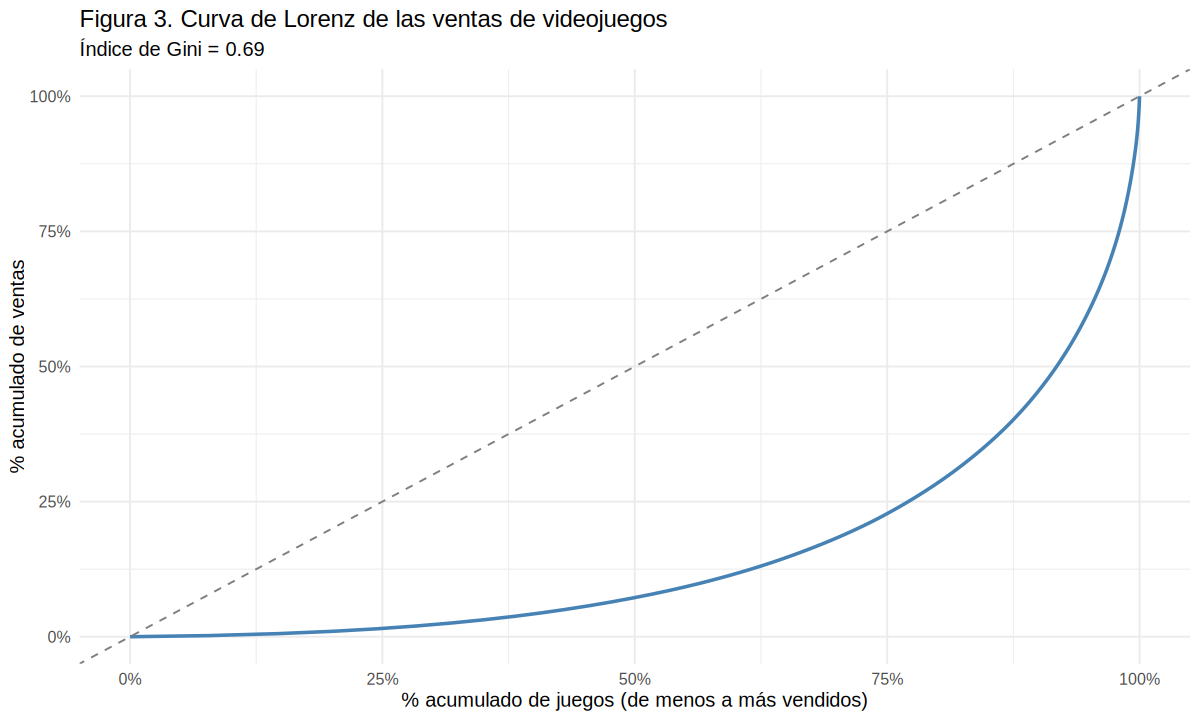

In [ ]:
lorenz <- tibble(v = sort(ventas$total_sales)) |>
  mutate(pct_juegos = row_number() / n(),
         pct_ventas = cumsum(v) / sum(v))

ggplot(lorenz, aes(pct_juegos, pct_ventas)) +
  geom_line(linewidth = 1, colour = "steelblue") +
  geom_abline(linetype = "dashed", colour = "grey50") +
  scale_x_continuous(labels = percent) + scale_y_continuous(labels = percent) +
  labs(title = "Figura 3. Curva de Lorenz de las ventas de videojuegos",
       subtitle = paste("Índice de Gini =", round(gini(ventas$total_sales), 2)),
       x = "% acumulado de juegos (de menos a más vendidos)", y = "% acumulado de ventas")

**Interpretación P1:**

Las ventas presentan una distribución muy asimétrica. La mediana es de 0,14 millones de unidades, mientras que la media alcanza 0,377 millones, casi el triple. Esta diferencia se debe a un pequeño número de superventas que eleva la media. La mitad de los videojuegos vende menos de 140.000 unidades.

La curva de Lorenz (Figura 3) se aleja mucho de la diagonal de igualdad, y el índice de Gini es de 0,685, lo que indica una concentración elevada. El 1 % de los juegos más vendidos acumula el 16,8 % de las ventas, el 10 % acumula el 54,5 % y el 20 % concentra el 71,5 %. El mercado está dominado comercialmente por un grupo reducido de títulos, mientras que la mayoría obtiene ventas modestas.

Este resultado condiciona el resto del análisis. Como la media no es representativa, en las preguntas siguientes se usan medianas, escala logarítmica y pruebas no paramétricas, como Kruskal-Wallis en lugar de ANOVA.

Limitación: cada observación es un juego en una plataforma concreta, no un título. Por ejemplo, GTA V aparece por separado en PS3, PS4 y X360. Además, solo se incluyen los juegos con ventas registradas. Si se agrupara por título y se incluyeran los juegos de ventas muy bajas, la concentración probablemente sería aún mayor.

Conexión con P2: una vez comprobado que unos pocos juegos concentran gran parte de las ventas, interesa averiguar si el género ayuda a explicar por qué unos videojuegos venden más que otros.

---
## P2. ¿Se asocia el género a vender más?

**Qué se quiere averiguar:** si las ventas típicas difieren entre géneros.
**Por qué importa:** el género es la decisión de producto más básica. Después de P1, interesa saber si algunos géneros tienen más probabilidad de producir éxitos.
**Técnica:** como las ventas no son normales (P1), se usa **Kruskal-Wallis** con tamaño del efecto ε², y comparaciones por pares de Wilcoxon con corrección de Holm.

In [ ]:
resumen_genero <- ventas |>
  group_by(genero) |>
  summarise(n = n(), mediana = median(total_sales), media = mean(total_sales),
            pct_superventas = mean(total_sales >= 1) * 100,   # % de juegos con >= 1 M
            ventas_totales = sum(total_sales)) |>
  arrange(desc(mediana))
resumen_genero

genero,n,mediana,media,pct_superventas,ventas_totales
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Action-Adventure,255,0.230,0.5823137,14.509804,148.49
Shooter,1374,0.210,0.7243668,18.049491,995.28
Sports,2479,0.210,0.4773134,11.738604,1183.26
Platform,901,0.190,0.3871032,9.322974,348.78
Music,138,0.175,0.3750000,7.246377,51.75
Action,2673,0.160,0.4205799,8.604564,1124.21
Fighting,856,0.160,0.3985164,10.981308,341.13
Racing,1346,0.150,0.3904235,10.995542,525.51
Otros,65,0.140,0.2864615,6.153846,18.62


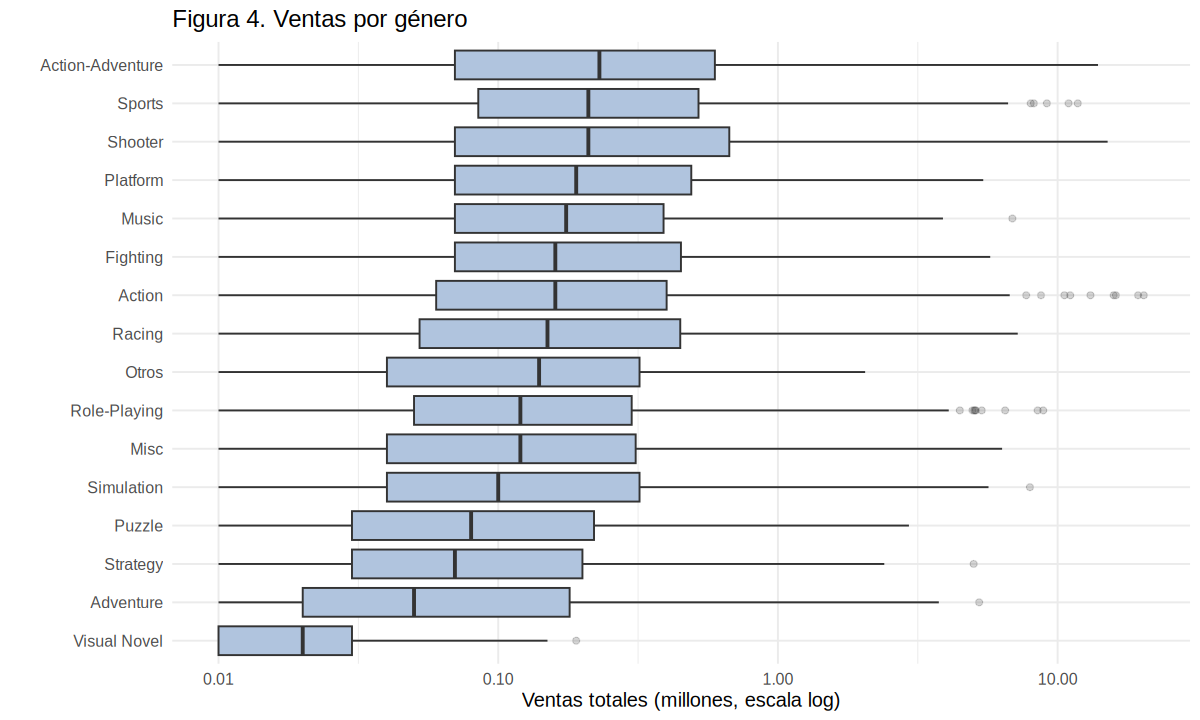

In [ ]:
ggplot(ventas, aes(x = reorder(genero, log_ventas, FUN = median), y = total_sales)) +
  geom_boxplot(fill = "lightsteelblue", outlier.alpha = 0.2) +
  scale_y_log10(labels = label_number(accuracy = 0.01)) +
  coord_flip() +
  labs(title = "Figura 4. Ventas por género",
       x = NULL, y = "Ventas totales (millones, escala log)")

In [ ]:
kw_genero <- kruskal.test(total_sales ~ genero, data = ventas)
kw_genero
epsilon2 <- unname(kw_genero$statistic) / (nrow(ventas) - 1)
cat("Tamaño del efecto epsilon^2 =", round(epsilon2, 3), "\n")

# Comparaciones por pares (p-valores ajustados por Holm)
pw <- pairwise.wilcox.test(ventas$total_sales, ventas$genero, p.adjust.method = "holm")
round(pw$p.value, 4)


	Kruskal-Wallis rank sum test

data:  total_sales by genero
Kruskal-Wallis chi-squared = 1360.9, df = 15, p-value < 2.2e-16


Tamaño del efecto epsilon^2 = 0.078 


,Action,Action-Adventure,Adventure,Fighting,Misc,Music,Platform,Puzzle,Racing,Role-Playing,Shooter,Simulation,Sports,Strategy,Visual Novel
Action-Adventure,0.0768,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
Adventure,0.0000,0.0000,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
Fighting,0.7645,1.0000,0.0000,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
Misc,0.0000,0.0000,0.0000,0.0000,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
Music,1.0000,1.0000,0.0000,1.0000,0.2467,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
Platform,0.0293,1.0000,0.0000,1.0000,0.0000,1.000,NA,NA,NA,NA,NA,NA,NA,NA,NA
Puzzle,0.0000,0.0000,0.0002,0.0000,0.0000,0.000,0.0000,NA,NA,NA,NA,NA,NA,NA,NA
Racing,1.0000,0.1477,0.0000,1.0000,0.0002,1.000,0.1578,0.0000,NA,NA,NA,NA,NA,NA,NA
Role-Playing,0.0000,0.0000,0.0000,0.0000,1.0000,0.245,0.0000,0.0000,6e-04,NA,NA,NA,NA,NA,NA
Shooter,0.0000,1.0000,0.0000,0.0779,0.0000,1.000,0.4814,0.0000,0e+00,0,NA,NA,NA,NA,NA


**Interpretación P2:**

La prueba de Kruskal-Wallis indica diferencias significativas en las ventas según el género (χ² = 1360,9; gl = 15; p < 0,001). El tamaño del efecto es moderado (ε² = 0,078): el género explica en torno al 8 % de la variabilidad de las ventas, medida en rangos, así que influye, pero deja sin explicar la mayor parte.

Las comparaciones por pares (Wilcoxon con corrección de Holm) permiten distinguir dos bloques (Figura 4). Shooter, Sports, Action-Adventure y Platform no difieren significativamente entre sí y tienen las medianas más altas (0,19–0,23 M). En el extremo opuesto están Strategy, Puzzle, Adventure y Visual Novel (0,02–0,08 M). La diferencia se nota todavía más en los superventas: el 18 % de los shooters supera el millón de unidades, frente al 1,4 % de los juegos de estrategia y ninguna novela visual. Algunos géneros tienen más probabilidad de producir los éxitos que concentran el mercado (P1).

La mediana y el volumen total no siempre coinciden. Action tiene una mediana moderada (0,16 M), pero es uno de los géneros con más ventas acumuladas porque reúne muchos títulos.

Conexión con P3: varios de los géneros con ventas más bajas, como Adventure y Visual Novel, son característicos del mercado japonés. Esto lleva a preguntarse si no venden «peor» en general, sino que dependen de un mercado más pequeño. Por eso, a continuación se estudia si las preferencias de género cambian según la región.

---
## P3. ¿Prefiere cada mercado géneros y fabricantes distintos?

**Qué se quiere averiguar:** si la relación entre género y éxito depende de la región. Para cada juego se toma la región donde más vende (`region_principal`).
**Por qué importa:** una editora no decide igual qué lanzar en Japón que en Norteamérica. Esto matiza los resultados de P2.
**Técnica:** tabla de contingencia, **chi-cuadrado de independencia**, V de Cramér y residuos estandarizados.

In [ ]:
reg <- ventas |> filter(region_principal != "Otros")

tabla_gen_reg <- table(reg$genero, reg$region_principal)
tabla_gen_reg
round(prop.table(tabla_gen_reg, margin = 2) * 100, 1)   # % de cada región por género

                  
                   Europa Japón Norteamérica
  Action              312   558         1792
  Action-Adventure     96    24          135
  Adventure           215   767          691
  Fighting             39   310          504
  Misc                198   534         1074
  Music                26    40           72
  Platform             97    90          708
  Puzzle              102   110          414
  Racing              275    71          994
  Role-Playing        102   717          589
  Shooter             242   115         1015
  Simulation          178   231          591
  Sports              378   417         1671
  Strategy            162   236          293
  Visual Novel          1   185           11
  Otros                14    15           36

                  
                   Europa Japón Norteamérica
  Action             12.8  12.6         16.9
  Action-Adventure    3.9   0.5          1.3
  Adventure           8.8  17.4          6.5
  Fighting            1.6   7.0          4.8
  Misc                8.1  12.1         10.1
  Music               1.1   0.9          0.7
  Platform            4.0   2.0          6.7
  Puzzle              4.2   2.5          3.9
  Racing             11.3   1.6          9.4
  Role-Playing        4.2  16.2          5.6
  Shooter             9.9   2.6          9.6
  Simulation          7.3   5.2          5.6
  Sports             15.5   9.4         15.8
  Strategy            6.6   5.3          2.8
  Visual Novel        0.0   4.2          0.1
  Otros               0.6   0.3          0.3

In [ ]:
v_cramer <- function(tab) {
  chi <- suppressWarnings(chisq.test(tab))
  sqrt(unname(chi$statistic) / (sum(tab) * (min(dim(tab)) - 1)))
}

chi_gen_reg <- chisq.test(tabla_gen_reg)
chi_gen_reg
cat("Frecuencias esperadas < 5:", sum(chi_gen_reg$expected < 5), "\n")
cat("V de Cramér =", round(v_cramer(tabla_gen_reg), 3), "\n")


	Pearson's Chi-squared test

data:  tabla_gen_reg
X-squared = 2542.8, df = 30, p-value < 2.2e-16


Frecuencias esperadas < 5: 0 
V de Cramér = 0.27 


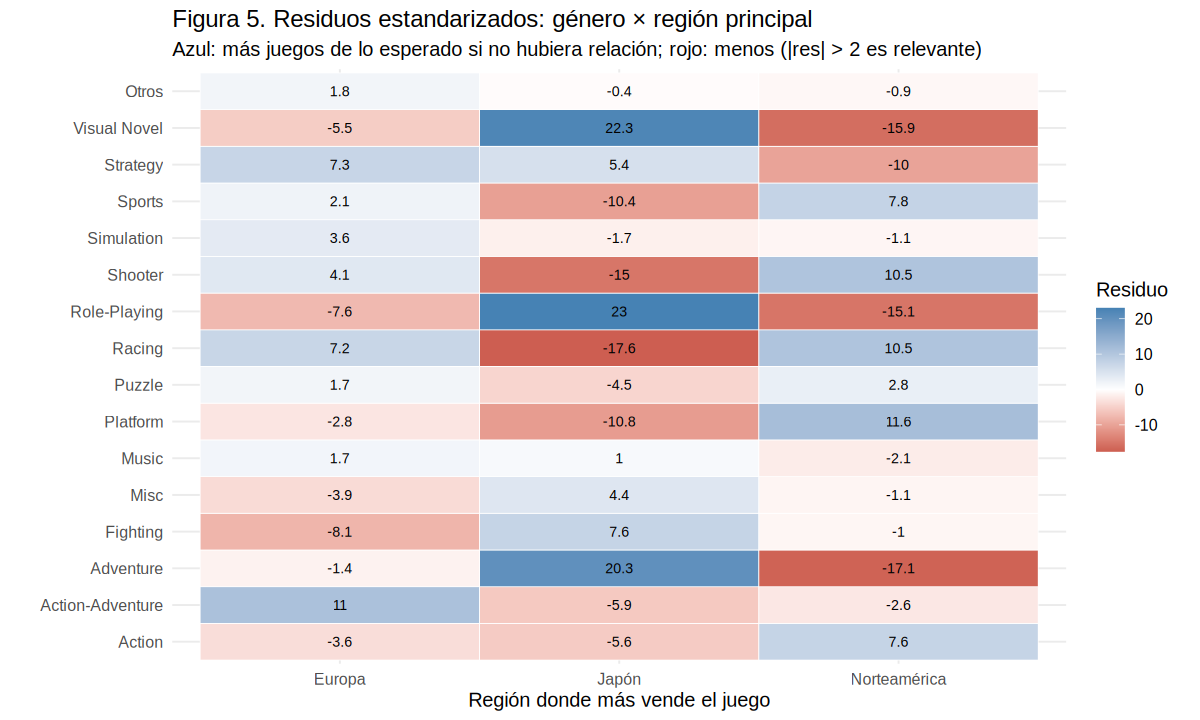

In [ ]:
residuos <- as.data.frame(chi_gen_reg$stdres) |>
  rename(genero = Var1, region = Var2, residuo = Freq)

ggplot(residuos, aes(region, genero, fill = residuo)) +
  geom_tile(colour = "white") +
  geom_text(aes(label = round(residuo, 1)), size = 3) +
  scale_fill_gradient2(low = "firebrick", mid = "white", high = "steelblue", midpoint = 0) +
  labs(title = "Figura 5. Residuos estandarizados: género × región principal",
       subtitle = "Azul: más juegos de lo esperado si no hubiera relación; rojo: menos (|res| > 2 es relevante)",
       x = "Región donde más vende el juego", y = NULL, fill = "Residuo")

In [ ]:
# Mismo análisis para el fabricante de la plataforma
# OJO: el peso de PC en Europa probablemente sea un artefacto de cómo VGChartz registra las ventas
# de PC (casi siempre en la columna pal_sales). Hay que comentarlo en el informe.
tabla_fab_reg <- table(reg$fabricante, reg$region_principal)
round(prop.table(tabla_fab_reg, margin = 2) * 100, 1)
chisq.test(tabla_fab_reg)
cat("V de Cramér =", round(v_cramer(tabla_fab_reg), 3), "\n")

           
            Europa Japón Norteamérica
  Microsoft   10.8   2.0         21.3
  Nintendo    22.0  33.6         40.0
  Otros        0.0   0.6          1.2
  PC          30.7   0.0          1.8
  Sega         0.0   5.5          0.1
  Sony        36.5  58.4         35.6


	Pearson's Chi-squared test

data:  tabla_fab_reg
X-squared = 5482.3, df = 10, p-value < 2.2e-16


V de Cramér = 0.396 


**Interpretación P3:**

Para cada juego se identifica la región donde más vende. La prueba chi-cuadrado muestra una asociación significativa entre género y región principal (χ² = 2542,8; gl = 30; p < 0,001), y ninguna frecuencia esperada es inferior a 5. La V de Cramér (0,27) indica una asociación moderada.

Los residuos estandarizados (Figura 5) muestran dónde se concentran las diferencias. En Japón están sobrerrepresentados Role-Playing (+23,0), Visual Novel (+22,3) y Adventure (+20,3). Los juegos de rol suponen el 16,2 % de los títulos que venden sobre todo en Japón, frente al 5,6 % en Norteamérica. En cambio, Racing (−17,6), Shooter (−15,0), Platform (−10,8) y Sports (−10,4) aparecen mucho menos de lo esperado en Japón: las carreras son solo el 1,6 % de sus títulos, frente al 11,3 % en Europa. Norteamérica destaca en Platform, Shooter y Racing (residuos entre +10 y +12). Europa destaca en Action-Adventure (+11,0) y Strategy (+7,3).

Esto confirma lo planteado al final de P2. Adventure y Visual Novel no venden necesariamente «peor», sino que dependen sobre todo del mercado japonés, que es más pequeño en volumen.

La asociación con el fabricante es todavía más fuerte (χ² = 5482,3; gl = 10; p < 0,001; V = 0,40). Sony está en el 58,4 % de los juegos que venden sobre todo en Japón, y Sega casi solo aparece en ese mercado. Microsoft supone el 21,3 % de los juegos de Norteamérica, frente al 2,0 % de los de Japón. El peso de PC en Europa (30,7 %) debe tomarse con cautela: probablemente se debe a cómo VGChartz registra las ventas de PC y no a una preferencia real.

Conexión con P4: las preferencias dependen del mercado. El siguiente paso es comprobar si son estables o si han cambiado entre 1995 y 2018.

---
## P4. ¿Han cambiado estas preferencias entre 1995 y 2018?

**Qué se quiere averiguar:** si el peso de cada género (y de cada fabricante) en las ventas ha evolucionado.
**Por qué importa:** si los patrones de P2 y P3 cambian con el tiempo, las conclusiones sobre "qué vende" dependen de la época.
**Técnica:** análisis temporal (cuotas de ventas por año) y chi-cuadrado género × periodo.
**Nota:** solo hay datos de ventas suficientes entre 1995 y 2018 (después hay menos de 40 juegos por año).

anio,n
<dbl>,<int>
2016,597
2017,663
2018,625
2019,34
2020,22


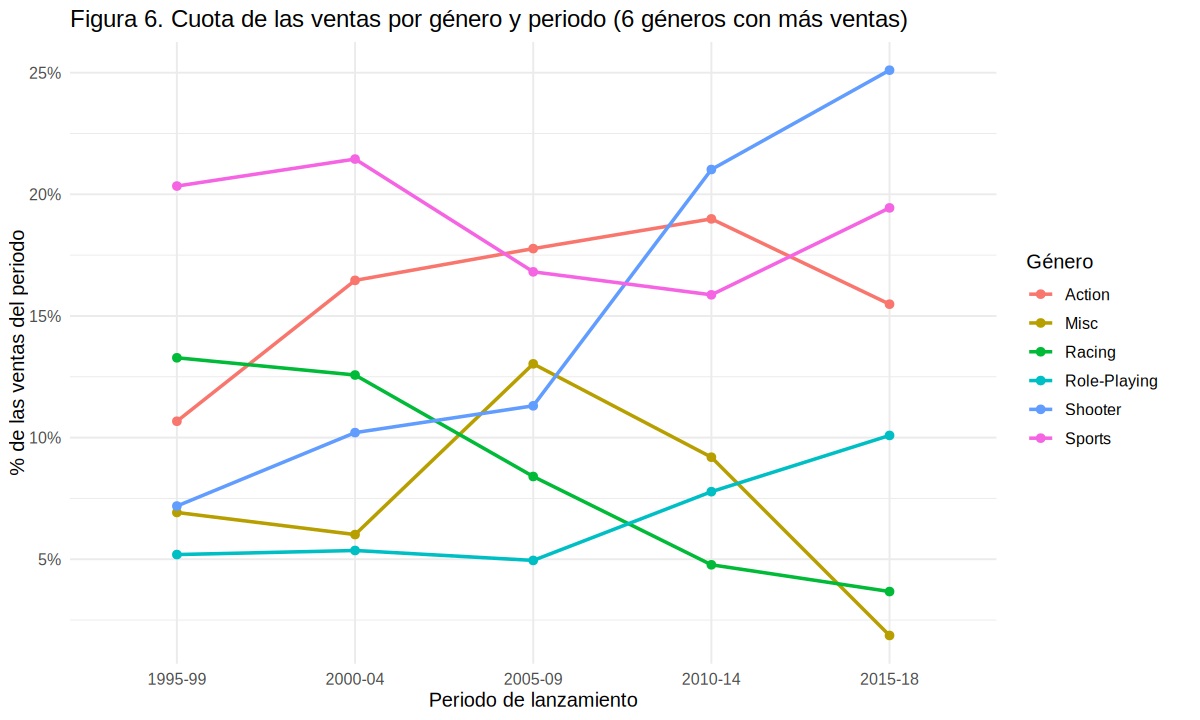

In [ ]:
count(ventas, anio) |> filter(anio >= 2016)    # justificación del corte en 2018

temp <- ventas |> filter(!is.na(periodo))

top_generos <- resumen_genero |> arrange(desc(ventas_totales)) |> slice_head(n = 6) |> pull(genero)

# Se agrupa por periodos de 5 años: la serie anual es muy ruidosa porque un solo superventas mueve la cuota
cuotas_per <- temp |>
  filter(genero %in% top_generos) |>
  group_by(periodo, genero) |>
  summarise(ventas = sum(total_sales)) |>
  left_join(temp |> group_by(periodo) |> summarise(total = sum(total_sales)), by = "periodo") |>
  mutate(cuota = ventas / total)

ggplot(cuotas_per, aes(periodo, cuota, colour = genero, group = genero)) +
  geom_line(linewidth = 1) + geom_point(size = 2) +
  scale_y_continuous(labels = percent) +
  labs(title = "Figura 6. Cuota de las ventas por género y periodo (6 géneros con más ventas)",
       x = "Periodo de lanzamiento", y = "% de las ventas del periodo", colour = "Género")

In [ ]:
tabla_gen_per <- table(temp$genero, temp$periodo)
round(prop.table(tabla_gen_per, margin = 2) * 100, 1)

# OJO: Action-Adventure, Music y Visual Novel no aparecen antes de 2010. Lo más probable es que
# VGChartz cambiara su clasificación de géneros, no que esos géneros no existieran.
# Para el contraste se excluyen los géneros con algún periodo vacío.
generos_estables <- rownames(tabla_gen_per)[apply(tabla_gen_per, 1, min) > 0 &
                                             rownames(tabla_gen_per) != "Otros"]
tabla_gen_per <- tabla_gen_per[generos_estables, ]
chi_gen_per <- chisq.test(tabla_gen_per)
cat("Frecuencias esperadas < 5:", sum(chi_gen_per$expected < 5), "\n")
chi_gen_per
cat("V de Cramér =", round(v_cramer(tabla_gen_per), 3), "\n")

                  
                   1995-99 2000-04 2005-09 2010-14 2015-18
  Action               8.1    14.0    15.1    14.6    21.2
  Action-Adventure     0.0     0.0     0.0     3.3     4.5
  Adventure            6.6     5.9    11.3    10.3    11.7
  Fighting            11.2     5.8     4.1     4.0     3.3
  Misc                 7.2     6.7    13.0    14.7     4.1
  Music                0.0     0.0     0.0     1.4     3.1
  Platform             5.3     8.8     4.8     3.1     4.0
  Puzzle               4.0     2.4     4.8     3.5     1.5
  Racing              10.9    12.8     7.1     4.9     6.3
  Role-Playing         7.1     6.1     7.1     8.2    11.9
  Shooter              9.5     9.5     7.2     7.8     6.6
  Simulation           4.5     4.2     7.3     5.5     5.3
  Sports              19.3    19.9    13.9    12.0     8.8
  Strategy             6.4     3.7     4.3     3.3     3.3
  Visual Novel         0.0     0.0     0.0     2.9     2.8
  Otros                0.0     0.1   

Frecuencias esperadas < 5: 0 



	Pearson's Chi-squared test

data:  tabla_gen_per
X-squared = 1246.2, df = 44, p-value < 2.2e-16


V de Cramér = 0.138 


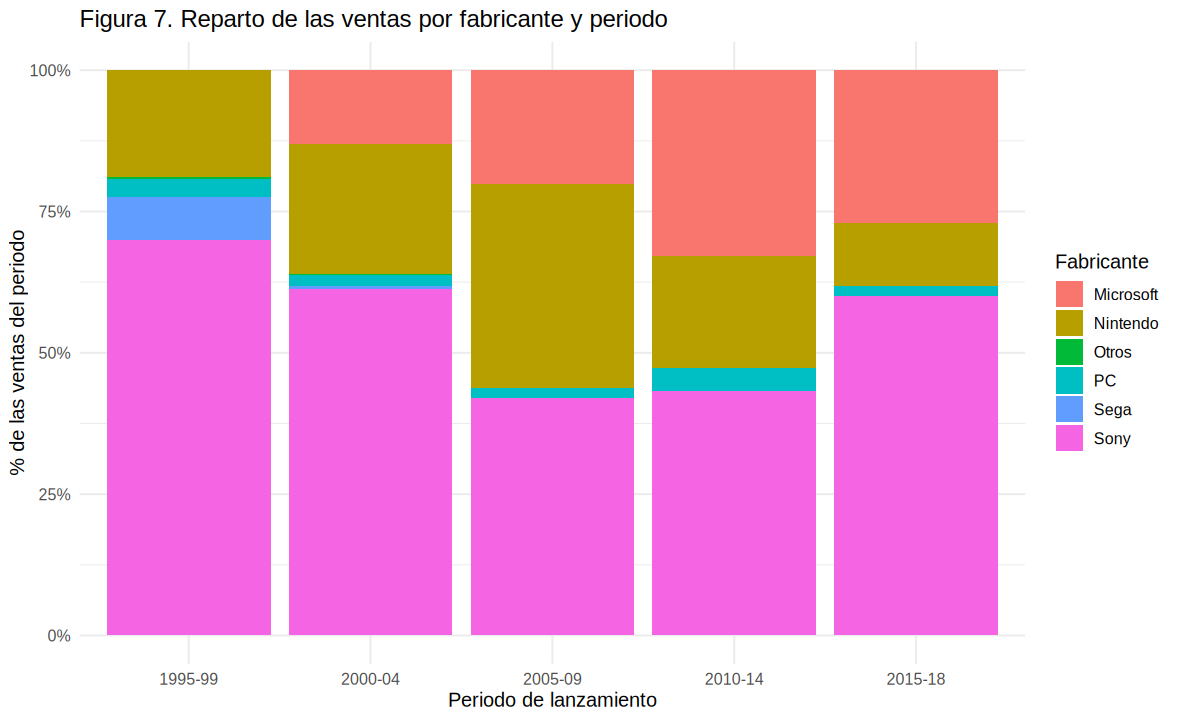

In [ ]:
cuotas_fab <- temp |>
  group_by(periodo, fabricante) |>
  summarise(ventas = sum(total_sales)) |>
  mutate(cuota = ventas / sum(ventas))

ggplot(cuotas_fab, aes(periodo, cuota, fill = fabricante)) +
  geom_col() +
  scale_y_continuous(labels = percent) +
  labs(title = "Figura 7. Reparto de las ventas por fabricante y periodo",
       x = "Periodo de lanzamiento", y = "% de las ventas del periodo", fill = "Fabricante")

**Interpretación P4:**

El análisis se limita a 1995-2018. Hasta 2018 hay unos 600 juegos con ventas por año, mientras que en 2019 y 2020 solo hay 34 y 22. Action-Adventure, Music y Visual Novel no aparecen antes de 2010, probablemente por un cambio en la clasificación de VGChartz, así que se excluyen del contraste.

La composición del catálogo por género cambia significativamente entre periodos (χ² = 1246,2; gl = 44; p < 0,001), con una asociación pequeña-moderada (V de Cramér = 0,138). La V resume todos los géneros a la vez y oculta cambios muy marcados en algunos de ellos.

La evolución de las ventas (Figura 6) muestra esos cambios con más claridad. Los shooters pasan del 7,2 % de las ventas en 1995-99 al 25,1 % en 2015-18 y se convierten en el género más vendido. Role-Playing duplica su peso (del 5,2 % al 10,1 %). En cambio, Racing cae del 13,3 % al 3,7 %. Misc tiene un pico en 2005-09 (13 %) y luego casi desaparece (1,9 %).

Comparar catálogo y ventas es revelador. El número de shooters lanzados apenas varía (residuos entre −3,4 y +3,0), pero su cuota de ventas se triplica. Los juegos deportivos son proporcionalmente menos en 2015-18 (residuo −6,8), pero mantienen en torno al 19 % de las ventas. En estos géneros, cada vez menos títulos se reparten más ventas, lo que conecta con la concentración observada en P1. Además, la posición destacada de los shooters en P2 es en gran parte un fenómeno reciente.

Por fabricantes (Figura 7), Sony concentra el 70 % de las ventas en 1995-99, baja al 42 % en 2005-09, cuando Nintendo alcanza su máximo (36 %), y se recupera hasta el 60 % en 2015-18. Microsoft entra en 2000-04 y llega al 33 % en 2010-14.

Conexión con P5: género, mercado y periodo se asocian con las ventas. Falta comprobar si la calidad percibida, medida por la nota de la crítica, también está relacionada con el éxito comercial.

---
## P5. ¿Se relaciona la nota de la crítica con las ventas? ¿Igual en todos los géneros?

**Qué se quiere averiguar:** si los juegos mejor valorados venden más y si esa relación cambia según el género.
**Por qué importa:** cierra el hilo. Tras ver factores de producto (género), mercado y tiempo, se comprueba si la calidad percibida añade algo.
**Técnica:** correlación de **Spearman** (las ventas no son normales), comparación por niveles de nota (Kruskal-Wallis) y correlación por género.
**Cuidado (sesgo de selección):** solo ~4.000 juegos tienen nota. Antes de analizarla se comprueba si esos juegos son representativos.

In [ ]:
# ¿Son distintos los juegos con nota de los que no la tienen?
ventas |> group_by(tiene_critica) |>
  summarise(n = n(), mediana_ventas = median(total_sales))
wilcox.test(total_sales ~ tiene_critica, data = ventas)

tiene_critica,n,mediana_ventas
<lgl>,<int>,<dbl>
FALSE,13553,0.11
TRUE,3964,0.32



	Wilcoxon rank sum test with continuity correction

data:  total_sales by tiene_critica
W = 15565893, p-value < 2.2e-16
alternative hypothesis: true location shift is not equal to 0



	Spearman's rank correlation rho

data:  critica$critic_score and critica$total_sales
S = 6624546168, p-value < 2.2e-16
alternative hypothesis: true rho is not equal to 0
sample estimates:
     rho 
0.361874 


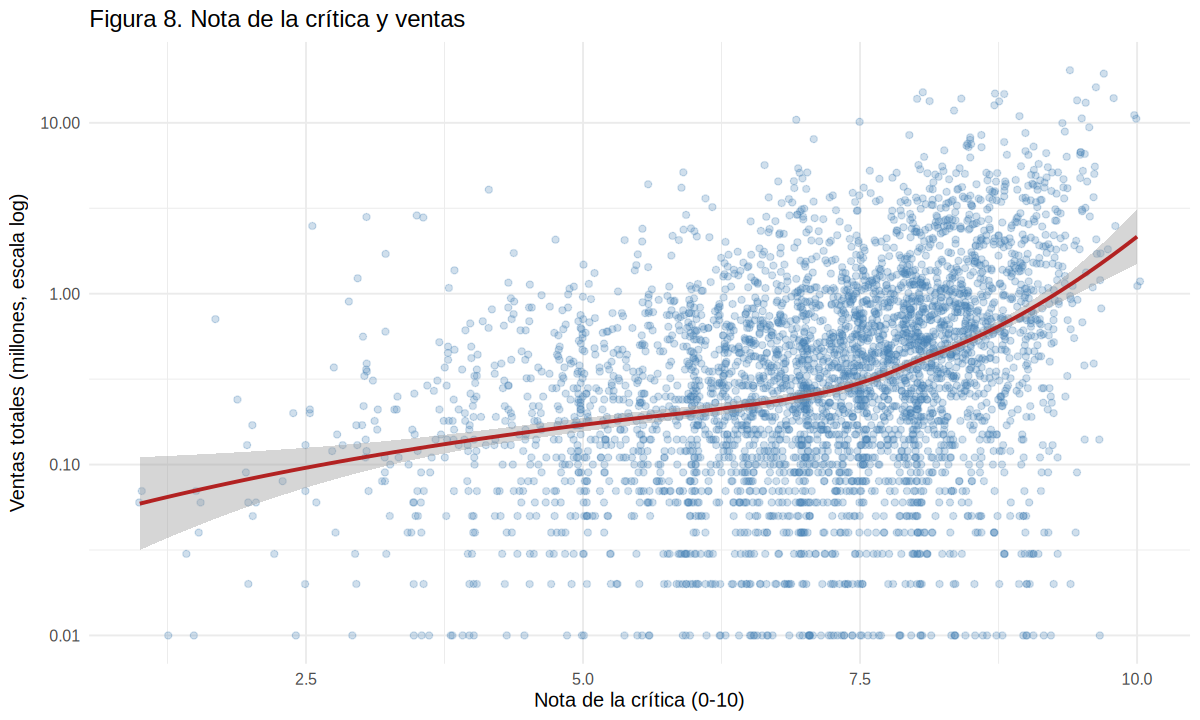

In [ ]:
critica <- ventas |> filter(tiene_critica)

cor.test(critica$critic_score, critica$total_sales, method = "spearman", exact = FALSE)

ggplot(critica, aes(critic_score, total_sales)) +
  geom_jitter(alpha = 0.25, width = 0.05, colour = "steelblue") +
  geom_smooth(method = "loess", formula = y ~ x, colour = "firebrick") +
  scale_y_log10(labels = label_number(accuracy = 0.01)) +
  labs(title = "Figura 8. Nota de la crítica y ventas",
       x = "Nota de la crítica (0-10)", y = "Ventas totales (millones, escala log)")

In [ ]:
critica <- critica |>
  mutate(nivel_critica = cut(critic_score, breaks = c(-Inf, 6, 8, Inf),
                             labels = c("Baja (<= 6)", "Media (6-8]", "Alta (> 8)")))

critica |> group_by(nivel_critica) |>
  summarise(n = n(), mediana = median(total_sales), pct_superventas = mean(total_sales >= 1) * 100)
kruskal.test(total_sales ~ nivel_critica, data = critica)

nivel_critica,n,mediana,pct_superventas
<fct>,<int>,<dbl>,<dbl>
Baja (<= 6),837,0.18,5.137395
Media (6-8],2035,0.29,14.938575
Alta (> 8),1092,0.69,38.003663



	Kruskal-Wallis rank sum test

data:  total_sales by nivel_critica
Kruskal-Wallis chi-squared = 465.83, df = 2, p-value < 2.2e-16


genero,n,rho,p_valor,p_ajustado
<fct>,<int>,<dbl>,<dbl>,<dbl>
Action,703,0.43474458,8.899274e-34,1.156906e-32
Sports,523,0.42822542,9.764390e-25,1.171727e-23
Misc,224,0.41761705,7.243631e-11,5.794905e-10
Action-Adventure,76,0.40306843,3.061291e-04,1.530646e-03
Fighting,217,0.40170133,8.046729e-10,5.632710e-09
Role-Playing,446,0.40128407,1.100150e-18,1.210165e-17
Adventure,217,0.36891166,2.120553e-08,1.272332e-07
Shooter,497,0.36713676,2.641217e-17,2.641217e-16
Racing,328,0.35996994,1.803799e-11,1.623419e-10


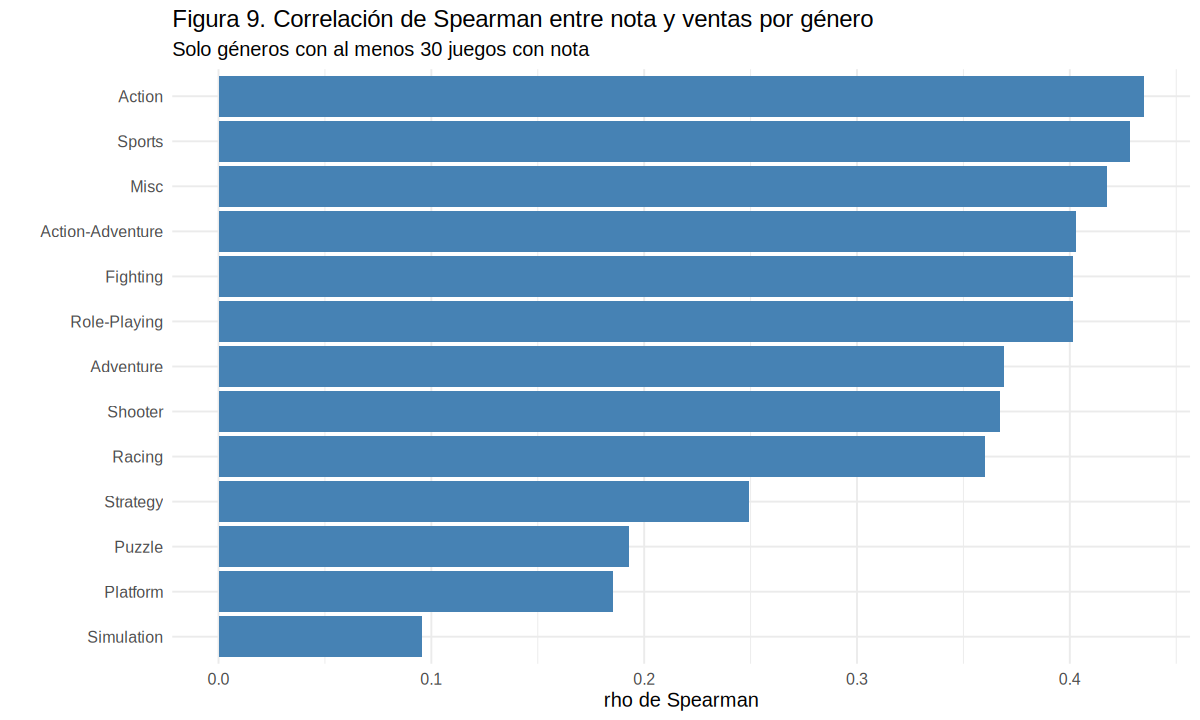

In [ ]:
cor_genero <- critica |>
  group_by(genero) |>
  filter(n() >= 30) |>
  summarise(n = n(),
            rho = cor(critic_score, total_sales, method = "spearman"),
            p_valor = suppressWarnings(cor.test(critic_score, total_sales, method = "spearman")$p.value)) |>
  mutate(p_ajustado = p.adjust(p_valor, method = "holm")) |>
  arrange(desc(rho))
cor_genero

ggplot(cor_genero, aes(reorder(genero, rho), rho)) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(title = "Figura 9. Correlación de Spearman entre nota y ventas por género",
       subtitle = "Solo géneros con al menos 30 juegos con nota",
       x = NULL, y = "rho de Spearman")

In [ ]:
# Casos que rompen el patrón: superventas con nota baja
critica |> filter(critic_score <= 6, total_sales >= 1) |>
  select(title, console, genero, critic_score, total_sales) |>
  arrange(desc(total_sales))

title,console,genero,critic_score,total_sales
<chr>,<chr>,<fct>,<dbl>,<dbl>
Medal of Honor: Rising Sun,PS2,Shooter,5.9,5.13
Michael Jackson: The Experience,Wii,Misc,5.6,4.37
Teenage Mutant Ninja Turtles,NES,Platform,5.9,4.17
Carnival Games,Wii,Misc,4.2,4.06
Cooking Mama: Cook Off,Wii,Simulation,5.9,2.89
Imagine: Babyz,DS,Simulation,3.5,2.87
Imagine: Fashion Designer,DS,Simulation,3.0,2.81
A Bug's Life,PS,Platform,3.6,2.79
Game Party,Wii,Misc,2.6,2.49


**Interpretación P5:**

Solo 3.964 juegos con ventas tienen nota de la crítica, y no son representativos. Su mediana de ventas es de 0,32 M, frente a 0,11 M en los que no tienen nota (Wilcoxon, p < 0,001). Por eso, los resultados describen sobre todo a los juegos más conocidos.

La correlación de Spearman entre nota y ventas es positiva y moderada (ρ = 0,362; p < 0,001; un 13 % de variabilidad compartida). Las diferencias entre niveles de nota son significativas (Kruskal-Wallis, χ² = 465,8; gl = 2; p < 0,001) y claras. La mediana pasa de 0,18 M con nota baja (≤ 6) a 0,29 M con nota media y 0,69 M con nota alta (> 8). El porcentaje de juegos que supera el millón de unidades sube del 5 % al 15 % y al 38 %. Las buenas críticas se asocian sobre todo a una mayor probabilidad de convertirse en superventas.

La relación no es igual en todos los géneros (Figura 9). Es más fuerte en Action, Sports, Misc, Fighting y Role-Playing (ρ ≈ 0,40–0,43) y débil en Strategy (0,25) y Platform (0,19). En Puzzle y Simulation no es significativa tras la corrección de Holm. Platform es un caso llamativo: era uno de los géneros con ventas más altas en P2, pero la crítica apenas se relaciona con ellas.

También hay superventas con nota baja, como Carnival Games, Michael Jackson: The Experience o Just Dance 3. Son sobre todo juegos casuales y familiares de Wii y DS, cuyo éxito no parece depender de la crítica, lo que coincide con el pico de Misc en 2005-09 (P4).

No puede afirmarse que una buena crítica cause más ventas. Los juegos de mayor presupuesto suelen tener a la vez más marketing, más visibilidad y más críticas, así que la relación puede deberse a factores comunes no medidos.

---
## Conclusiones

Las ventas están muy concentradas en pocos títulos (P1). Algunos géneros tienen más probabilidad de producir éxitos (P2), pero esas diferencias dependen en parte del mercado (P3) y de la época (P4). La nota de la crítica se asocia a vender más (P5), aunque con intensidad distinta según el género y con importantes excepciones. Ningún factor explica por sí solo el éxito comercial. Cada uno tiene un efecto moderado y los datos solo permiten hablar de asociaciones, no de causas.

---
## Limitaciones

- Solo el ~30 % de los juegos del fichero tiene ventas, y solo el ~6 % tiene ventas y nota a la vez.
- VGChartz estima las ventas (no son datos oficiales) y, en general, solo registra unidades físicas. Esto infrarrepresenta PC y los juegos digitales.
- Casi no hay ventas registradas después de 2018, así que los datos no describen el mercado actual.
- `region_principal` resume en una sola categoría la región donde más vende cada juego, y se pierde información.
- Los juegos con nota de la crítica no son una muestra aleatoria (ver P5).